In [ ]:
# 02 manifold — Wang 2019 GBM. Score the embryonic modules, read module geography (Gate 2),
# choose branching vs non-branching topology from the embedding + signatures, fit + root the trajectory.
import os, sys, glob, io, contextlib, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
import re
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; from numpy.linalg import svd
c = xy - xy.mean(0); u, sng, vt = svd(c, full_matrices=False)
print('UMAP aspect ratio (major/minor std): %.2f' % (sng[0]/sng[1]))

malignant manifold: 9634 cells
UMAP aspect ratio (major/minor std): 1.45


In [ ]:
# score Gast / pSom / Crest with the union control pool
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('RAW global means:', {m: round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})
# graph-smooth (knn-averaging) for reading geography on a sparse 10x manifold (raw shown in the deliverable)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 100/104 genes present
RAW global means: {'Gast': -0.002, 'pSom': 0.008, 'Crest': -0.007}


In [ ]:
# GATE 2 read #1 — module geography (smoothed spatial correlations)
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\n-> Gast/pSom co-vary (r>0, NOT anti-correlated) and both oppose Crest.')
print('   Gast/pSom do not diverge into competing arms -> single collapsed axis -> NON-BRANCHING.')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.16
  Crest_sm vs Gast_sm: r = -0.49
  Crest_sm vs pSom_sm: r = -0.87

-> Gast/pSom co-vary (r>0, NOT anti-correlated) and both oppose Crest.
   Gast/pSom do not diverge into competing arms -> single collapsed axis -> NON-BRANCHING.


In [ ]:
# proliferation orthogonality + per-lobe biology (settle each sub-region BEFORE the topology call)
adata.obs['cyc_score'] = adata.obs[['S_score','G2M_score']].max(axis=1)
print('proliferation orthogonality (cycling score vs modules):')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  cyc vs {m}: r = {np.corrcoef(adata.obs.cyc_score, adata.obs[m])[0,1]:+.2f}')
print('\nper-lobe smoothed developmental means:')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm','cyc_score']].mean().round(4).to_string())
print('\n-> |corr(cycling, modules)| <= 0.12: the developmental axis is orthogonal to proliferation;')
print('   no lobe is a cycling compartment confounding Gast. Keep the whole manifold (no scoping needed).')
sub = adata

proliferation orthogonality (cycling score vs modules):
  cyc vs Gast_sm: r = -0.05
  cyc vs pSom_sm: r = +0.12
  cyc vs Crest_sm: r = -0.12

per-lobe smoothed developmental means:
      Gast_sm  pSom_sm  Crest_sm  cyc_score
lobe                                       
0     -0.0041  -0.0018    0.0015    -0.0289
1     -0.0035   0.0050   -0.0045    -0.0181
2     -0.0030   0.0124   -0.0098    -0.0332
3     -0.0033   0.0175   -0.0148    -0.0238
4     -0.0062   0.0163   -0.0116     0.0225
5     -0.0036   0.0040   -0.0053    -0.0023

-> |corr(cycling, modules)| <= 0.12: the developmental axis is orthogonal to proliferation;
   no lobe is a cycling compartment confounding Gast. Keep the whole manifold (no scoping needed).


In [ ]:
# topology fit: NON-BRANCHING -> scFates curve. Nodes scale with cells; verify fold-freeness.
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
for N in [15, 20, 30]:
    ad2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(ad2, Nodes=N, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(ad2)
    print(f'curve Nodes={N}: tips={tips} forks={forks} fold self-approach ratio={sa:.2f} (>1 = fold-free)')
NODES = 20
print('selected Nodes =', NODES, '(fold-free at every N tested; 20 matches the Brain/10x scale)')

curve Nodes=15: tips=2 forks=0 fold self-approach ratio=2.96 (>1 = fold-free)
curve Nodes=20: tips=2 forks=0 fold self-approach ratio=2.80 (>1 = fold-free)
curve Nodes=30: tips=2 forks=0 fold self-approach ratio=2.42 (>1 = fold-free)
selected Nodes = 20 (fold-free at every N tested; 20 matches the Brain/10x scale)


In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=NODES, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'committed curve: {tips} tips, {forks} forks, fold ratio = {sa:.2f}')
assert forks == 0 and sa > 1, 'topology check failed'
# root from developmental order: Gast/pSom-high, Crest-low tip is the origin (Crest is late/terminal)
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
ROOT = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', ROOT, '(Gast/pSom-high, Crest-low developmental origin)')

committed curve: 2 tips, 0 forks, fold ratio = 2.80
tip 0: Gast=-0.0053 pSom=-0.0022 Crest=+0.0023
tip 2: Gast=-0.0025 pSom=+0.0150 Crest=-0.0127
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)


In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, ROOT); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for sn in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho, p = spearmanr(t, sub.obs[sn]); print(f'  {sn}: rho = {rho:+.3f}  p = {p:.1e}')
print('-> pSom falls and Crest rises along pseudotime; Gast flat; cycling orthogonal.')

gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.061  p = 2.7e-09
  pSom_sm: rho = -0.615  p = 0.0e+00
  Crest_sm: rho = +0.492  p = 0.0e+00
  cyc_score: rho = +0.013  p = 2.0e-01
-> pSom falls and Crest rises along pseudotime; Gast flat; cycling orthogonal.


In [ ]:
# continuity on an INDEPENDENT embedding (diffusion), not the UMAP the curve was fit on
sc.tl.diffmap(sub, n_comps=15)
dc1 = sub.obsm['X_diffmap'][:,1]
rho_dc, _ = spearmanr(t, dc1)
print(f'continuity: corr(pseudotime, diffusion DC1) = {rho_dc:+.2f} on an embedding the curve was NOT fit on')
print('monotonic on the independent embedding -> continuous, fold-free confirmed.')
# orientation: make low pseudotime -> left for the house linear panel
xy = sub.obsm['X_umap'].copy(); xyr = xy.copy()
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0: xyr[:,0] = -xyr[:,0]; r = -r
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (pseudotime increases left->right)')

continuity: corr(pseudotime, diffusion DC1) = -0.98 on an embedding the curve was NOT fit on
monotonic on the independent embedding -> continuous, fold-free confirmed.
orientation: corr(x_lin, pseudotime) = +0.96 (pseudotime increases left->right)


saved manifold.pdf (root on left, curve edges rendered, fold-free)


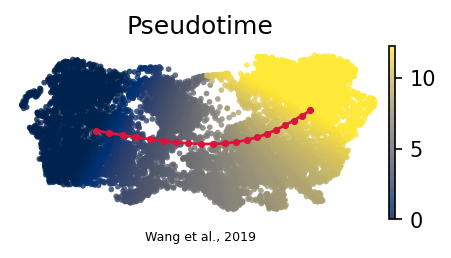

In [ ]:
# manifold.pdf — plot on the linear-oriented layout and render the fitted curve edges over the cells
F = np.asarray(sub.uns['graph']['F']); Bc = np.asarray(sub.uns['graph']['B'])
ii, jj = np.where(np.triu(Bc>0))
flip = not np.allclose(sub.obsm['X_umap'][:,0], sub.obsm['X_umap_lin'][:,0])
Fl = F.copy()
if flip: Fl[0] = -Fl[0]                       # curve nodes under the same orientation flip
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']   # reference pattern: linear basis
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
for a, b in zip(ii, jj):
    ax.plot([Fl[0,a],Fl[0,b]], [Fl[1,a],Fl[1,b]], '-', color='crimson', lw=1.3, zorder=5)
ax.scatter(Fl[0], Fl[1], c='crimson', s=6, zorder=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.pdf (root on left, curve edges rendered, fold-free)')

In [ ]:
# sanitize non-serializable ElPiGraph uns entry, save manifold.h5ad
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', sub.shape)

saved manifold.h5ad (9634, 26409)
